# MLOps e Versionamento — Previsão de preços de casas na Califórnia

## 1. Problema Inicial e Requisitos de Negócio

### Problema Inicial

O desafio central deste projeto é prever o valor mediano de imóveis em distritos da Califórnia utilizando dados demográficos, geográficos e características estruturais médias de cada região (bloco censitário). A capacidade de antecipar esses valores permite precificar portfólios de forma dinâmica, identificar distritos subvalorizados para investimento e planejar políticas de habitação acessível.

### Requisitos de Negócio

* Predição Contínua (Regressão): O sistema deve fornecer uma estimativa monetária para a variável MedHouseVal (Valor Mediano das Casas) com base nas 8 variáveis preditoras disponíveis.
* Interpretabilidade Geográfica: O modelo precisa integrar com precisão o impacto das coordenadas de Latitude e Longitude, identificando áreas nobres (como regiões costeiras ou grandes centros urbanos) e áreas de menor valorização.

* Métricas de Sucesso: O desempenho do modelo será avaliado por métricas de regressão padrão. Uma meta aceitável de negócio é atingir um coeficiente de determinação (R²) superior a 0.75 na base de teste.
* Relação Causa-Efeito (Explorabilidade): Mais do que apenas prever o preço, a liderança de negócios precisa entender a importância de cada variável (ex: o quanto o aumento da renda mediana MedInc afeta o preço do imóvel comparado à idade da casa HouseAge).

### Usuários-Chave da Solução

* Analistas de Investimento Imobiliário: Usam as previsões para identificar distritos com alto potencial de valorização.
* Planejadores Urbanos: Utilizam os dados interpretados para identificar regiões com déficit de moradia acessível ou superpopulação.

## Instalação de dependências

Execute esta célula uma vez, se necessário. Depois reinicie o kernel.

In [1]:
# !pip install -r requirements.txt

## Importação de pacotes

In [2]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance

from xgboost import XGBRegressor

import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

PROJECT_DIR = Path.cwd() / "california_housing_mlops"
PROJECT_DIR.mkdir(exist_ok=True)
MLRUNS_DIR = PROJECT_DIR / "mlruns"
MLRUNS_DIR.mkdir(exist_ok=True)

# Tracking local usando SQLite
MLFLOW_DB = PROJECT_DIR / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB.resolve().as_posix()}")

# Cria ou seleciona o experimento
mlflow.set_experiment("CaliforniaHousingExperiment")

print(f"Projeto: {PROJECT_DIR}")
print(f"MLflow Tracking URI: {mlflow.get_tracking_uri()}")
print(f"Banco de dados: {MLFLOW_DB.resolve()}")

print(f"Projeto: {PROJECT_DIR}")
print(f"MLflow Tracking URI: {mlflow.get_tracking_uri()}")

Projeto: C:\Users\jpcavalcante\OneDrive - Stefanini\Documents\fgv\MLOps e Versionamento\códigos\california_housing_mlops
MLflow Tracking URI: sqlite:///C:/Users/jpcavalcante/OneDrive - Stefanini/Documents/fgv/MLOps e Versionamento/códigos/california_housing_mlops/mlflow.db
Banco de dados: C:\Users\jpcavalcante\OneDrive - Stefanini\Documents\fgv\MLOps e Versionamento\códigos\california_housing_mlops\mlflow.db
Projeto: C:\Users\jpcavalcante\OneDrive - Stefanini\Documents\fgv\MLOps e Versionamento\códigos\california_housing_mlops
MLflow Tracking URI: sqlite:///C:/Users/jpcavalcante/OneDrive - Stefanini/Documents/fgv/MLOps e Versionamento/códigos/california_housing_mlops/mlflow.db


## 2. Validação e Governança dos Dados

Obtenção e preparação dos dados que alimentarão o modelo preditivo de Machine Learning.

### Dicionário de Dados

| Nome da Variável | Tipo de Variável | Descrição | Unidade / Formato |
| :--- | :--- | :--- | :--- |
| **MedInc** | Preditora (Feature) | Renda mediana das famílias na região do bloco. | Dezenas de milhares de dólares (ex: `3.87` = \$38.700) |
| **HouseAge** | Preditora (Feature) | Idade mediana das casas na região do bloco. | Anos |
| **AveRooms** | Preditora (Feature) | Média de cômodos por habitação. | Número decimal |
| **AveBedrms** | Preditora (Feature) | Média de quartos por habitação. | Número decimal |
| **Population** | Preditora (Feature) | População total residente na região do bloco. | Número inteiro |
| **AveOccup** | Preditora (Feature) | Média de ocupantes por domicílio. | Número decimal |
| **Latitude** | Preditora (Feature) | Coordenada de latitude geográfica do bloco. | Graus decimais |
| **Longitude** | Preditora (Feature) | Coordenada de longitude geográfica do bloco. | Graus decimais |
| **MedHouseVal** | **Alvo (Target)** | Valor mediano das casas na região do bloco. | Centenas de milhares de dólares (ex: `1.55` = \$155.000) |

## Carregamento da base California Housing

In [3]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

TARGET = "MedHouseVal"
print(f"Formato: {df.shape}")
display(df.head())
display(df.describe().T)

Formato: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


## 3. Processamentos dos Dados

### 3.1 Valores nulos


In [4]:
null_report = (
    df.isna()
      .sum()
      .rename("nulos")
      .to_frame()
      .assign(percentual=lambda x: 100 * x["nulos"] / len(df))
)
display(null_report)

if null_report["nulos"].sum() == 0:
    print("Não foram encontrados valores nulos.")
else:
    print("Há valores nulos; o pipeline contém imputação para lidar com eles.")

,nulos,percentual
MedInc,0,0.0
HouseAge,0,0.0
AveRooms,0,0.0
AveBedrms,0,0.0
Population,0,0.0
AveOccup,0,0.0
Latitude,0,0.0
Longitude,0,0.0
MedHouseVal,0,0.0


Não foram encontrados valores nulos.


### 3.2 Outliers pelo método IQR

#### Calcular o IQR
O IQR representa a amplitude da metade central dos dados.
$$IQR = Q3 - Q1$$

*   **Q1 (Primeiro Quartil):** 25% dos dados estão abaixo deste valor.
*   **Q3 (Terceiro Quartil):** 75% dos dados estão abaixo deste valor.

#### Definir os Limites de Controle
Os limites determinam a fronteira onde os dados deixam de ser considerados normais e passam a ser classificados como outliers.

*   **Limite Inferior (LI):** 
    $$LI = Q1 - (1.5 \times IQR)$$
*   **Limite Superior (LS):** 
    $$LS = Q3 + (1.5 \times IQR)$$

In [5]:
numeric_original_cols = df.select_dtypes(include=np.number).columns.tolist()

outlier_rows = []
for col in numeric_original_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_rows.append({
        "feature": col,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "limite_inferior": lower,
        "limite_superior": upper,
        "n_outliers": int(count),
        "pct_outliers": 100 * count / len(df),
    })

outlier_report = pd.DataFrame(outlier_rows).sort_values("n_outliers", ascending=False)
display(outlier_report.style.format({
    "q1": "{:.3f}", "q3": "{:.3f}", "iqr": "{:.3f}",
    "limite_inferior": "{:.3f}", "limite_superior": "{:.3f}",
    "pct_outliers": "{:.2f}%"
}))

# plt.figure(figsize=(14, 6))
# sns.boxplot(data=df[numeric_original_cols], orient="h", showfliers=False)
# plt.title("Distribuição das variáveis numéricas (outliers ocultos para facilitar a visualização)")
# plt.tight_layout()
# plt.show()

,feature,q1,q3,iqr,limite_inferior,limite_superior,n_outliers,pct_outliers
3,AveBedrms,1.006,1.100,0.093,0.866,1.240,1424,6.90%
4,Population,787.000,1725.000,938.000,-620.000,3132.000,1196,5.79%
8,MedHouseVal,1.196,2.647,1.451,-0.981,4.824,1071,5.19%
5,AveOccup,2.430,3.282,0.853,1.151,4.561,711,3.44%
0,MedInc,2.563,4.743,2.180,-0.706,8.013,681,3.30%
2,AveRooms,4.441,6.052,1.612,2.023,8.470,511,2.48%
1,HouseAge,18.000,37.000,19.000,-10.500,65.500,0,0.00%
6,Latitude,33.930,37.710,3.780,28.260,43.380,0,0.00%
7,Longitude,-121.800,-118.010,3.790,-127.485,-112.325,0,0.00%


### 3.3 Engenharia de Features

Criação de novas features:
* **RoomsPerHousehold:** 
* **BedroomsPerRoom:**
* **PopulationPerHousehold:**
* **MedIncLog:**

In [6]:
data = df.copy()

data["RoomsPerHousehold"] = data["AveRooms"] / data["AveOccup"].clip(lower=0.1)
data["BedroomsPerRoom"] = data["AveBedrms"] / data["AveRooms"].clip(lower=0.1)
data["PopulationPerHousehold"] = data["Population"] / data["AveOccup"].clip(lower=0.1)

# Faixas de renda.
data["IncomeCategory"] = pd.cut(
    data["MedInc"],
    bins=[-np.inf, 2, 4, 6, np.inf],
    labels=["Baixa", "Média-baixa", "Média-alta", "Alta"]
).astype("category")

display(data.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,RoomsPerHousehold,BedroomsPerRoom,PopulationPerHousehold,IncomeCategory
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,2.732919,0.146591,126.0,Alta
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,2.956685,0.155797,1138.0,Alta
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,2.957661,0.129516,177.0,Alta
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,2.283154,0.184458,219.0,Média-alta
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,2.879646,0.172096,259.0,Média-baixa


### 3.4 Correlação e associação das features com o target

- **Spearman:** para target contínuo × features contínuas
- **Mutual Information:** para feature categórica × target contínuo: mede dependência, inclusive não linear.

In [7]:
original_feature_cols = [c for c in df.columns if c != TARGET]
continuous_cols = original_feature_cols + ["RoomsPerHousehold", "BedroomsPerRoom", "PopulationPerHousehold"]
categorical_cols = ["IncomeCategory"]

print('Target:', TARGET)
print('\n')

print('Features categóricas:')
for i in categorical_cols:
    print(i)
print('\n')

print('Features contínuas:')
for i in continuous_cols:
    print(i)

Target: MedHouseVal


Features categóricas:
IncomeCategory


Features contínuas:
MedInc
HouseAge
AveRooms
AveBedrms
Population
AveOccup
Latitude
Longitude
RoomsPerHousehold
BedroomsPerRoom
PopulationPerHousehold


,feature,spearman_rho,p_value
0,MedInc,0.6768,0.000e+00
8,RoomsPerHousehold,0.3998,0.000e+00
9,BedroomsPerRoom,-0.3313,0.000e+00
2,AveRooms,0.2634,0.000e+00
5,AveOccup,-0.2566,1.289e-307
6,Latitude,-0.1657,4.995e-127
3,AveBedrms,-0.1252,7.188e-73
10,PopulationPerHousehold,0.1127,2.299e-59
1,HouseAge,0.0749,4.844e-27
7,Longitude,-0.0697,1.241e-23


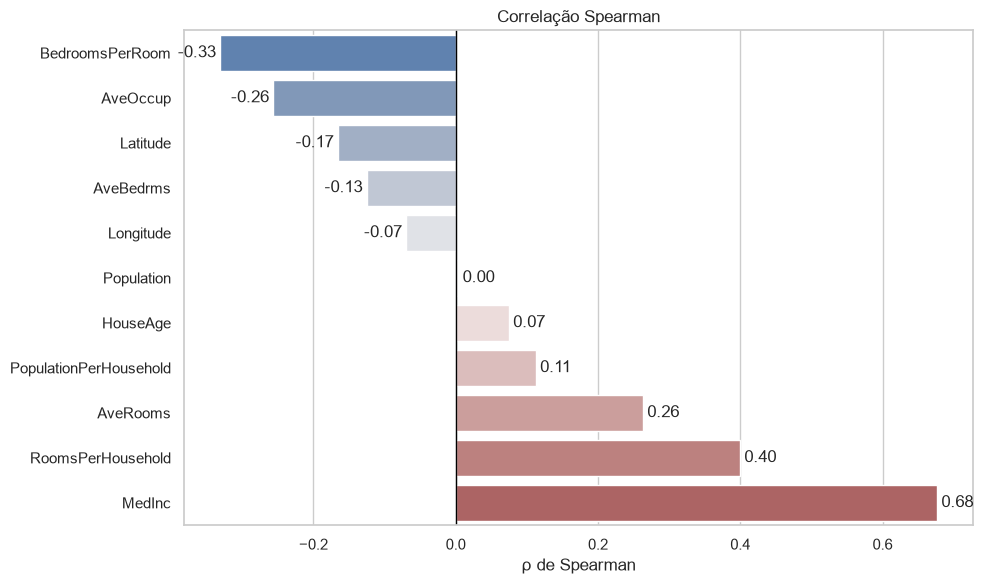

In [8]:
target = data[TARGET]

spearman_rows = []
for col in continuous_cols:
    valid = data[[col, TARGET]].dropna()
    rho, p_value = spearmanr(valid[col], valid[TARGET])
    spearman_rows.append({"feature": col, "spearman_rho": rho, "p_value": p_value})

spearman_df = (
    pd.DataFrame(spearman_rows)
    .assign(abs_rho=lambda x: x["spearman_rho"].abs())
    .sort_values("abs_rho", ascending=False)
    .drop(columns="abs_rho")
)
display(spearman_df.style.format({"spearman_rho": "{:.4f}", "p_value": "{:.3e}"}))

plt.figure(figsize=(10, 6))
plot_df = spearman_df.sort_values("spearman_rho")

ax = sns.barplot(data=plot_df, x="spearman_rho", y="feature", palette="vlag")
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", padding=3)


plt.axvline(0, color="black", linewidth=1)
plt.title("Correlação Spearman")
plt.xlabel("ρ de Spearman")
plt.ylabel("")
plt.tight_layout()
plt.show()

,feature,mutual_information
0,IncomeCategory,0.3237


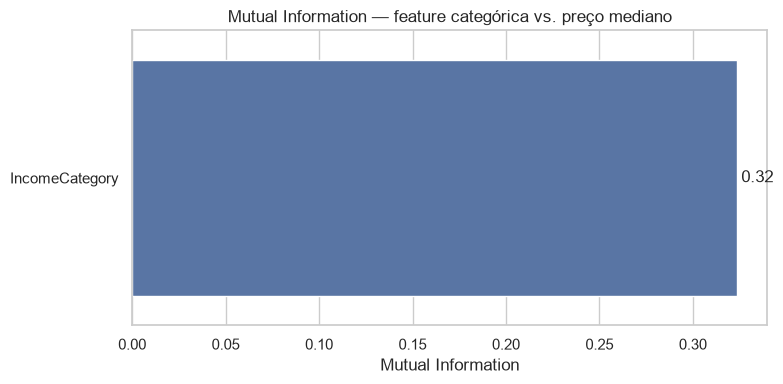

In [9]:
# Codifica as categorias somente para o cálculo da MI (não é o encoding do modelo).
mi_input = data[categorical_cols].copy()
for col in categorical_cols:
    mi_input[col] = pd.Categorical(mi_input[col]).codes

mi_values = mutual_info_regression(
    mi_input,
    target,
    discrete_features=[True] * len(categorical_cols),
    random_state=RANDOM_STATE,
)
mi_df = pd.DataFrame({"feature": categorical_cols, "mutual_information": mi_values})
display(mi_df.style.format({"mutual_information": "{:.4f}"}))

plt.figure(figsize=(8, 4))

ax = sns.barplot(data=mi_df.sort_values("mutual_information", ascending=False),
            x="mutual_information", y="feature", color="#4C72B0")
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", padding=3)
    
plt.title("Mutual Information — feature categórica vs. preço mediano")
plt.xlabel("Mutual Information")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 4. Separação em treino e teste

In [10]:
X = data.drop(columns=[TARGET])
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Treino: {X_train.shape[0]:} linhas.")
print(f"Teste:  {X_test.shape[0]:} linhas.")

Treino: 16512 linhas.
Teste:  4128 linhas.


## 5. Pipeline: imputação, normalização, padronização, One-Hot Encoding e Modelagem

In [11]:
# Pipeline para a transformação de feautures contínuas
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("minmax", MinMaxScaler()),
    ("standard", StandardScaler()),
])

# Pipeline para a transformação de feautures categórica
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# Definição do processador de colunas que aplicarão os pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, continuous_cols),
        ("cat", categorical_transformer, categorical_cols),
    ],
    remainder="drop",
)

# Criação de pipeline de modelo de acordo com o tipo de algoritmo de modelagem.
MODEL = 'xgboost'
if MODEL == 'ridge':
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("ridge", Ridge(alpha=10.0))
    ])

if MODEL == 'xgboost':
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("xgboost", XGBRegressor())
    ])

## 6. Treinamento, rastreabilidade e versionamento no MLflow

In [12]:
REGISTERED_MODEL_NAME = "CaliforniaHousing"
ARTIFACT_PATH = "pipeline"

with mlflow.start_run(run_name="california-housing") as run:
    run_id = run.info.run_id

    model_pipeline.fit(X_train, y_train)
    y_pred = model_pipeline.predict(X_test)
    
    metrics = {
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAPE_percent": mean_absolute_percentage_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred)
    }

    mlflow.log_params({
        "algorithm": MODEL,
        "test_size": 0.20,
        "random_state": RANDOM_STATE,
        "numeric_scaling": "MinMaxScaler -> StandardScaler",
        "categorical_encoding": "OneHotEncoder(handle_unknown=ignore)",
        "feature_engineering": "ratios + log(MedInc) + IncomeCategory",
    })
    mlflow.log_metrics(metrics)

    signature = infer_signature(X_train, model_pipeline.predict(X_train))
    
    model_info = mlflow.sklearn.log_model(
        sk_model=model_pipeline,
        name=ARTIFACT_PATH,
        signature=signature,
        input_example=X_train.head(3),
        registered_model_name=REGISTERED_MODEL_NAME,
        serialization_format="pickle",
    )

print(f"Run ID: {run_id}")
print(f"Model URI do run: {model_info.model_uri}")
print("Modelo registrado no MLflow com sucesso.")

2026/11/06 16:11:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Run ID: 0e5a4a7ec37a44168884962d5f85f495
Model URI do run: models:/m-fdf1c1d205e3469f89cafdbde50d6514
Modelo registrado no MLflow com sucesso.


Registered model 'CaliforniaHousing' already exists. Creating a new version of this model...
Created version '3' of model 'CaliforniaHousing'.


## 7. Métricas de avaliação

O target está em centenas de milhares de dólares. Assim, por exemplo, um MAE de `0.50` representa aproximadamente US$ 50 mil.


,Métrica,Valor
0,MAE,0.30870
1,MSE,0.21846
2,RMSE,0.46739
3,MAPE_percent,0.17698
4,R2,0.83329


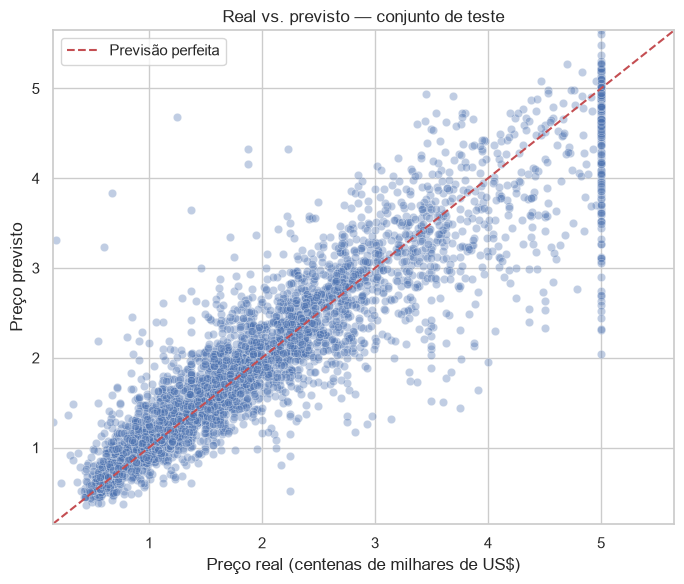

In [13]:
metrics_df = pd.DataFrame(
    [{"Métrica": key, "Valor": value} for key, value in metrics.items()]
)
display(metrics_df.style.format({"Valor": "{:.5f}"}))

plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.35)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Previsão perfeita")
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("Preço real (centenas de milhares de US$)")
plt.ylabel("Preço previsto")
plt.title("Real vs. previsto — conjunto de teste")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Consulta da versão do modelo registrada

In [14]:
client = mlflow.MlflowClient()
versions = client.search_model_versions(f"name='{REGISTERED_MODEL_NAME}'")
current_version = next(v.version for v in versions if v.run_id == run_id)

print(f"Modelo registrado: {REGISTERED_MODEL_NAME}")
print(f"Versão desta execução: {current_version}")
print(f"URI de carregamento: models:/{REGISTERED_MODEL_NAME}/{current_version}")

# Validação de carregamento da versão registrada.
versioned_model = mlflow.sklearn.load_model(
    f"models:/{REGISTERED_MODEL_NAME}/{current_version}"
)
print("Validação: modelo carregado do Model Registry com sucesso.")

Modelo registrado: CaliforniaHousing
Versão desta execução: 3
URI de carregamento: models:/CaliforniaHousing/3
Validação: modelo carregado do Model Registry com sucesso.


## 9. Importância por permutação (explicabilidade básica)

,feature,importance_mae
6,Latitude,0.835226
7,Longitude,0.770008
0,MedInc,0.251920
5,AveOccup,0.090481
9,BedroomsPerRoom,0.062539
1,HouseAge,0.043243
8,RoomsPerHousehold,0.031127
2,AveRooms,0.028553
4,Population,0.012882
10,PopulationPerHousehold,0.009787


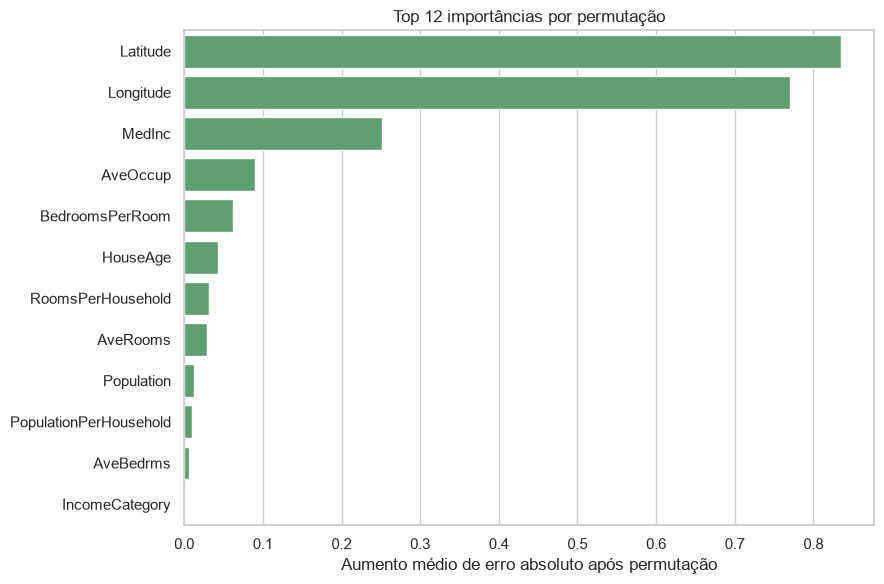

In [15]:
perm = permutation_importance(
    model_pipeline, X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error", n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mae": perm.importances_mean,
}).sort_values("importance_mae", ascending=False)

display(importance_df.head(12))
plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df.head(12), x="importance_mae", y="feature", color="#55A868")
plt.title("Top 12 importâncias por permutação")
plt.xlabel("Aumento médio de erro absoluto após permutação")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 10. Interface funcional em Streamlit

Após criar o arquivo, execute no terminal:

```bash
streamlit run california_housing_mlops/app.py
```

In [16]:

app_code = f'''from pathlib import Path

import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import streamlit as st

st.set_page_config(
    page_title="Previsão de Casas - Califórnia",
    page_icon="🏠"
)

st.title("Previsão de preços de casas na Califórnia")
st.caption("Regressão com pipeline versionado no MLflow")

# ============================================================
# 1. Configuração do projeto e do MLflow
# ============================================================

PROJECT_DIR = Path(__file__).resolve().parent
MLFLOW_DB = PROJECT_DIR / "mlflow.db"

mlflow.set_tracking_uri(
    f"sqlite:///{MLFLOW_DB.resolve().as_posix()}"
)

MODEL_NAME = "{REGISTERED_MODEL_NAME}"
MODEL_VERSION = "{current_version}"
MODEL_URI = f"models:/{{MODEL_NAME}}/{{MODEL_VERSION}}"
MODEL = "{MODEL}"

# ============================================================
# 2. Carregamento do modelo
# ============================================================

@st.cache_resource
def load_model():
    return mlflow.sklearn.load_model(MODEL_URI)


try:
    model = load_model()
except Exception as e:
    st.error("Não foi possível carregar o modelo do MLflow.")
    st.exception(e)
    st.info(f"Banco de dados configurado: {{MLFLOW_DB}}")
    st.stop()

st.info(
    f"Modelo em uso: **{{MODEL_NAME}} — algoritmo {{MODEL}} — versão {{MODEL_VERSION}}**"
)


# ============================================================
# 3. Formulário de entrada
# ============================================================

with st.form("prediction_form"):
    col1, col2 = st.columns(2)

    with col1:
        medinc = st.number_input(
            "MedInc — renda mediana",
            min_value=0.0, value=3.87, step=0.01
        )
        houseage = st.number_input(
            "HouseAge — idade média",
            min_value=1.0, value=28.0, step=1.0
        )
        averooms = st.number_input(
            "AveRooms — cômodos médios",
            min_value=0.1, value=5.43, step=0.01
        )
        avebedrms = st.number_input(
            "AveBedrms — quartos médios",
            min_value=0.1, value=1.10, step=0.01
        )

    with col2:
        population = st.number_input(
            "Population — população",
            min_value=1.0, value=1425.0, step=1.0
        )
        aveoccup = st.number_input(
            "AveOccup — ocupação média",
            min_value=0.1, value=3.07, step=0.01
        )
        latitude = st.number_input(
            "Latitude", value=35.63, format="%.4f"
        )
        longitude = st.number_input(
            "Longitude", value=-119.57, format="%.4f"
        )

    submitted = st.form_submit_button("Estimar preço")


# ============================================================
# 4. Engenharia de atributos e previsão
# ============================================================

if submitted:
    income_category = pd.cut(
        [medinc],
        bins=[-np.inf, 2, 4, 6, np.inf],
        labels=["Baixa", "Média-baixa", "Média-alta", "Alta"]
    )[0]

    model_input = pd.DataFrame([{{ 
        "MedInc": medinc,
        "HouseAge": houseage,
        "AveRooms": averooms,
        "AveBedrms": avebedrms,
        "Population": population,
        "AveOccup": aveoccup,
        "Latitude": latitude,
        "Longitude": longitude,
        "RoomsPerHousehold": averooms / max(aveoccup, 0.1),
        "BedroomsPerRoom": avebedrms / max(averooms, 0.1),
        "PopulationPerHousehold": population / max(aveoccup, 0.1),
        "MedIncLog": np.log1p(medinc),
        "IncomeCategory": str(income_category),
    }}])

    try:
        prediction_in_100k_usd = model.predict(model_input)[0]
        predicted_usd = max(0, prediction_in_100k_usd * 100_000)

        st.success(
            f"Preço estimado: **US$ {{predicted_usd:,.0f}}**"
        )
        st.caption(
            f"Saída do modelo: {{prediction_in_100k_usd:.3f}} "
            "(unidade = centenas de milhares de US$)"
        )

    except Exception as e:
        st.error("Erro ao realizar a previsão.")
        st.exception(e)
'''

app_path = PROJECT_DIR / "app.py"
app_path.write_text(app_code, encoding="utf-8")

print(f"Aplicação criada em: {app_path}")
print(f"Banco SQLite esperado: {PROJECT_DIR / 'mlflow.db'}")
print(f"Execute: streamlit run \"{app_path}\"")


Aplicação criada em: C:\Users\jpcavalcante\OneDrive - Stefanini\Documents\fgv\MLOps e Versionamento\códigos\california_housing_mlops\app.py
Banco SQLite esperado: C:\Users\jpcavalcante\OneDrive - Stefanini\Documents\fgv\MLOps e Versionamento\códigos\california_housing_mlops\mlflow.db
Execute: streamlit run "C:\Users\jpcavalcante\OneDrive - Stefanini\Documents\fgv\MLOps e Versionamento\códigos\california_housing_mlops\app.py"


# Informações úteis da Califórnia

* Latitude mínima (sul): 32° 30′ N (ou aproximadamente 32,51° N)
* Latitude máxima (norte): 42° 00′ N (ou aproximadamente 42,01° N)
* Longitude mínima (oeste): 124° 24′ O (ou aproximadamente -124,65° O)
* Longitude máxima (leste): 114° 08′ O (ou aproximadamente -114,13° O